In [1]:
from sklearn.datasets import load_iris

In [2]:
iris = load_iris()

In [3]:
import pandas as pd
df = pd.DataFrame(iris.data , columns =iris.feature_names)
df['target'] = iris.target

In [4]:
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [5]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [6]:
df.shape

(150, 5)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [9]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [11]:
df['target'].value_counts(normalize=True)

,proportion
target,
0,0.333333
1,0.333333
2,0.333333


In [12]:
df['target'].value_counts()

,count
target,
0,50
1,50
2,50


In [13]:
X = df.drop('target', axis = 1 )
y = df['target']

In [17]:
X.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='object')

In [20]:
y.shape
X.shape

(150, 4)

In [23]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X , y , test_size = 0.2 , random_state = 42 , stratify = y)

In [24]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(criterion="gini", random_state = 42 )

In [25]:
model.fit(X_train , y_train)

DecisionTreeClassifier(random_state=42)

In [26]:
y_pred = model.predict(X_test)

In [31]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test , y_pred)
print(f'accuracy score is {round(accuracy*100)}%')


accuracy score is 93%


In [33]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test , y_pred)
print(cm)

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [34]:
from sklearn.metrics import classification_report
cr = classification_report(y_test , y_pred)
print(cr)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



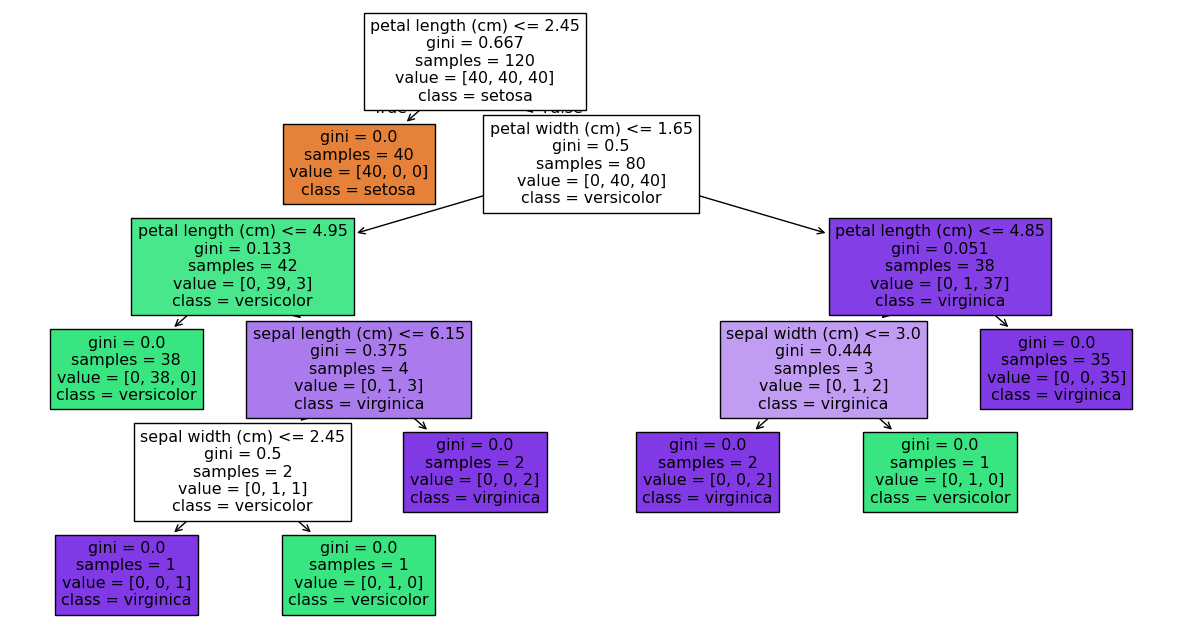

In [35]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(15,8))
plot_tree(model , feature_names = X.columns , class_names = iris.target_names , filled = True)
plt.show()

In [36]:
train_accuracy = model.score(X_train , y_train)
test_accuracy = model.score(X_test , y_test)

In [37]:
train_accuracy

1.0

In [38]:
test_accuracy

0.9333333333333333

In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
depths = [1, 2, 3, 4, 5, 6, 7, 8, 10]
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth,criterion="gini",random_state=42)
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)



In [40]:
depth

10

In [41]:
train_acc

1.0

In [42]:
test_acc

0.9333333333333333

In [43]:
train_scores = []
test_scores = []
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth,criterion="gini",random_state=42 )
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

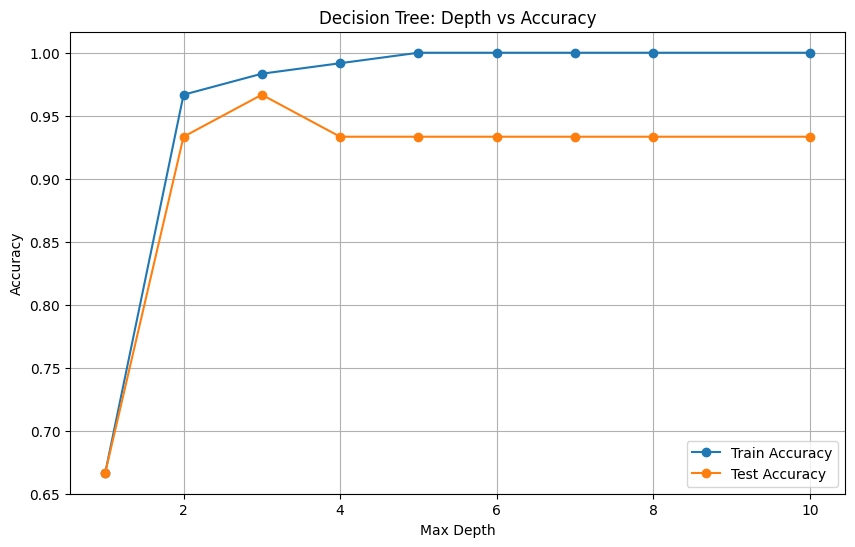

In [44]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(depths, train_scores, marker="o", label="Train Accuracy")
plt.plot(depths, test_scores, marker="o", label="Test Accuracy")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Depth vs Accuracy")
plt.legend()
plt.grid()

plt.show()

In [45]:
split_values = [2, 5, 10, 20, 30]
for value in split_values:
    model = DecisionTreeClassifier(min_samples_split=value,random_state=42 )
    model.fit(X_train, y_train)
    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)

In [46]:
from sklearn.model_selection import cross_val_score
model = DecisionTreeClassifier(random_state=42)
scores = cross_val_score(model,X,y,cv=5,scoring="accuracy")

print("CV Scores:", scores)
print("Mean CV Accuracy:", scores.mean())

CV Scores: [0.96666667 0.96666667 0.9        0.93333333 1.        ]
Mean CV Accuracy: 0.9533333333333334


In [47]:
from sklearn.model_selection import GridSearchCV
model = DecisionTreeClassifier(random_state=42)
param_grid = {"max_depth": [2, 3, 4, 5, 6, 7, 8],"min_samples_split": [2, 5, 10],
"min_samples_leaf": [1, 2, 4]}

In [48]:
grid_search = GridSearchCV(model,param_grid,cv=5,scoring="accuracy")
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'max_depth': [2, 3, 4, 5, 6, 7, 8],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [49]:
print(grid_search.best_params_)

{'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [50]:
best_model = grid_search.best_estimator_

In [51]:
final_accuracy = best_model.score(X_test, y_test)

print("Final Test Accuracy:", final_accuracy)

Final Test Accuracy: 0.9333333333333333


In [52]:
import pandas as pd
importance = pd.DataFrame({"Feature": X.columns,"Importance": best_model.feature_importances_})
importance = importance.sort_values("Importance",ascending=False)
print(importance)

             Feature  Importance
2  petal length (cm)    0.565639
3   petal width (cm)    0.411154
1   sepal width (cm)    0.016878
0  sepal length (cm)    0.006329
